## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Santiago Camacho Jimenez" # @param {"type":"string"}
carnet = 1000116319 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**


Una empresa de transporte urbano necesita representar su red de estacions. Cada estacion es un vertice y cada conexion directa entre dos estaciones es una arista. El sistema debe mostrar la red, recorrerla con BFS y DFS desde cualquier estacion, encontrar la ruta con menos conexiones entre dos estaciones y permitir agregar una estacion nueva cons sus conexiones.

## 2) Requerimientos **[2 pts]**




Requerimientos Funcionales
- Representar la red con una lista
- Mostrar cada estacion con sus vecinas directas
- Recorrer la red con BFS desde una estacion, mostrando orden y nivel
- Recorrer la red con DFS desde una estacion
- Permitir elegir la estacion inicial y mostrar error si no existe
- Encontrar la ruta con menos conexiones entre origen y destino

Requerimientos no Funcionales
- Cada conexion se guarda en ambos sentidos
- Sin conexiones duplicadas
- Cada estacion se visita una sola vez por recorrido
- Mensajes claros ante errores de entrada

## 3) Historias de usuario **[2 pts]**



Historia de usuario 1
- Como operador quiero ver cada estacion con sus vecinas directas para conocer su red
   - Criterios: Se listan 7 estaciones, cada conexion aparece en ambas estaciones

Historia de usuario 2
- Como operador quiero recorrer la red con BFS desde una estacion, para ver que tan lejos esta cada una
  - Criterios: Se muestra el orden de visita y el nivel, ninguna estacion se repite

Historia de usuario 3
- Como operador quiero recorrer la red con DFS desde una estacion para explorar la red en profundidad
  - Criterios: Se visita cada estacion una sola vez, si la estacion no existe se informa un error

Historia de usuario 4
- Como pasajero quiero la ruta con menos conexiones entre dos estaciones para viajar mas rapido
  - Criterios: Se muestra la ruta y la cantidad de conexiones, si no hay ruta el sistema lo indica

Historia de usuario 5
- Como administrador quiero agregar una estacion nueva con sus conexiones para reflejar la expansion
  - Criterios: Se conecta con al menos 2 estaciones existentes  y no se duplican conexiones.
  

## 4) Diagramas de flujo **[5 pts]**


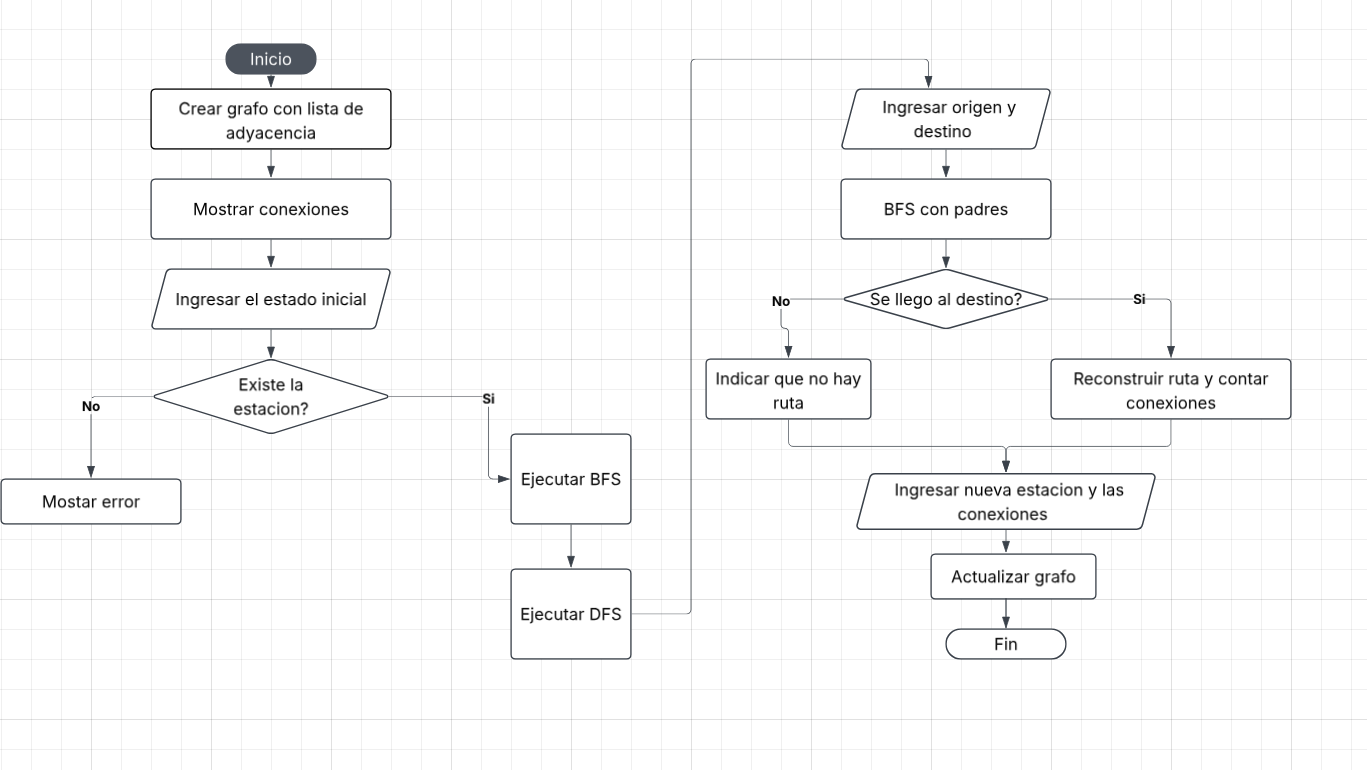

El programa construye el grafo, lo muestra y pide una estación inicial. Si existe, ejecuta BFS y DFS . Luego pide origen y destino y usa BFS guardando el padre de cada estación para reconstruir la ruta más corta. Finalmente agrega una estación nueva con sus conexiones y repite las operaciones sobre la red actualizada.

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
   - Cada estación entra una sola vez a la cola o se visita una sola vez. Cada lista de adyacencia se recorre una vez, como el grafo es no dirigido, cada arista se revisa 2 veces.
   
     Búsqueda en el conjunto de visitados y operaciones de cola: O(1).
- Función T[n]
   - T(n)= a*n^2 + b*n +c
- Mejor y peor caso con gráfica
  - Mejor caso: La ruta minima se detiene de inmediato
  - Peor caso: El destino es la ultima estacion en visitarse o la estacion no exite
  


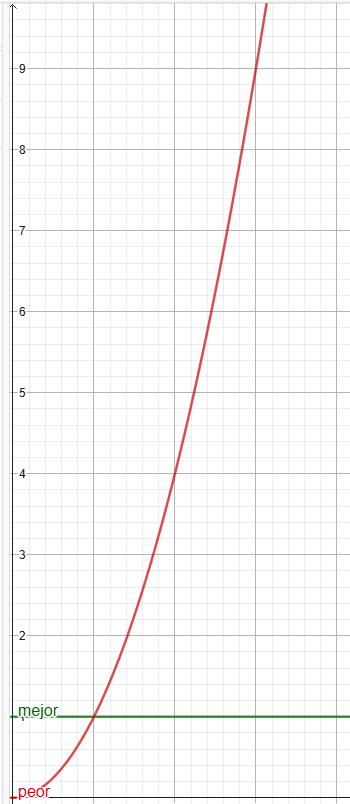

## 6) Código funcional **[15 pts]**



In [ ]:
from collections import deque

# mi grafo para la tarea
g = {}

def conectar(n1, n2):
    if n1 not in g:
        g[n1] = []
    if n2 not in g:
        g[n2] = []

    if n2 not in g[n1]:
        g[n1].append(n2)
    if n1 not in g[n2]:
        g[n2].append(n1)

def armar_red():
    g.clear()
    estaciones_base = ["Central", "Norte", "Museo", "Parque", "Universidad", "Hospital", "Terminal"]
    for est in estaciones_base:
        g[est] = []

    conectar("Central", "Norte")
    conectar("Central", "Museo")
    conectar("Norte", "Parque")
    conectar("Norte", "Universidad")
    conectar("Museo", "Hospital")
    conectar("Universidad", "Terminal")
    conectar("Hospital", "Terminal")

def imprimir_red():
    for llave in g:
        vecs = ", ".join(g[llave])
        print(llave + " -> " + vecs)

def hacer_bfs(ini):
    visitados = [ini] # uso lista en vez de set pa' probar
    cola_aux = deque([(ini, 0)])
    historial = []

    while len(cola_aux) > 0:
        nodo_act, nivel_act = cola_aux.popleft()
        historial.append((nodo_act, nivel_act))

        for vecino in g[nodo_act]:
            if vecino not in visitados:
                visitados.append(vecino)
                cola_aux.append((vecino, nivel_act + 1))
    return historial

def hacer_dfs(nodo_actual, vis=None, res=None):
    if vis is None:
        vis = []
        res = []
    vis.append(nodo_actual)
    res.append(nodo_actual)

    for vecino in g[nodo_actual]:
        if vecino not in vis:
            hacer_dfs(vecino, vis, res)
    return res

def buscar_camino(comienzo, meta):
    if comienzo not in g or meta not in g:
        return None

    padres_dic = {comienzo: None}
    q = deque([comienzo])

    while q:
        actual = q.popleft()
        if actual == meta:
            break
        for vecino in g[actual]:
            if vecino not in padres_dic:
                padres_dic[vecino] = actual
                q.append(vecino)

    if meta not in padres_dic:
        return None

    camino_final = []
    actual = meta
    while actual is not None:
        camino_final.append(actual)
        actual = padres_dic[actual]

    camino_final.reverse() # voltear la lista a mano
    return camino_final

def mostrar_bfs_menu(ini):
    datos = hacer_bfs(ini)
    print("BFS desde " + ini + ":")
    cadena_res = ""
    for x, n in datos:
        cadena_res += x + " -> "
    print(cadena_res[:-4])

    max_niv = datos[-1][1]
    for n in range(max_niv + 1):
        print("Nivel " + str(n) + ":")
        nodos_nivel = []
        for x, niv in datos:
            if niv == n:
                nodos_nivel.append(x)
        print(", ".join(nodos_nivel))

def mostrar_dfs_menu(ini):
    lista_dfs = hacer_dfs(ini)
    print("DFS desde " + ini + ":")
    print(" -> ".join(lista_dfs))

def menu():
    armar_red()
    while True:
        print("\n")
        print(" MENU RED TRANSPORTE ")
        print("1. Mostrar red")
        print("2. BFS Central")
        print("3. DFS Central")
        print("4. BFS y DFS otra estacion")
        print("5. Buscar ruta corta")
        print("6. Agregar estacion")
        print("0. Salir")

        print("Elige una opcion:")
        opcion = input()
        opcion = opcion.strip()

        if opcion == "1":
            imprimir_red()

        elif opcion == "2":
            mostrar_bfs_menu("Central")

        elif opcion == "3":
            mostrar_dfs_menu("Central")

        elif opcion == "4":
            print("Ingresa la estacion inicial:")
            inicio = input()
            inicio = inicio.strip()
            if inicio in g:
                mostrar_bfs_menu(inicio)
                mostrar_dfs_menu(inicio)
            else:
                print("Esa estacion no existe")

        elif opcion == "5":
            print("Estacion de salida:")
            orig = input()
            orig = orig.strip()

            print("Estacion de llegada:")
            dest = input()
            dest = dest.strip()

            if orig in g and dest in g:
                res_ruta = buscar_camino(orig, dest)
                if res_ruta is None:
                    print("No hay ruta posible")
                else:
                    print("Ruta:")
                    print(" -> ".join(res_ruta))
                    print("Total conexiones: " + str(len(res_ruta) - 1))
            else:
                print("Alguna estacion no existe")

        elif opcion == "6":
            print("Escribe el nombre de la nueva estacion:")
            nueva_est = input()
            nueva_est = nueva_est.strip()

            if nueva_est == "" or nueva_est in g:
                print("Nombre invalido o ya existe")
                continue

            print("Escribe las conexiones separadas por coma:")
            txt_vecinas = input()
            txt_vecinas = txt_vecinas.strip()

            lista_v = [v.strip() for v in txt_vecinas.split(",")]
            if len(lista_v) < 2:
                print("Necesita minimo 2 conexiones")
                continue

            valido = True
            for v in lista_v:
                if v not in g:
                    valido = False

            if not valido:
                print("Alguna vecina no existe en la red")
                continue

            g[nueva_est] = []
            for v in lista_v:
                conectar(nueva_est, v)

            print("Listo, estacion agregada")
            imprimir_red()

        elif opcion == "0":
            print("Saliendo del programa...")
            break

        else:
            print("Opcion mala, intenta de nuevo")

if __name__ == "__main__":
    menu()



 MENU RED TRANSPORTE 
1. Mostrar red
2. BFS Central
3. DFS Central
4. BFS y DFS otra estacion
5. Buscar ruta corta
6. Agregar estacion
0. Salir
Elige una opcion:
1
Central -> Norte, Museo
Norte -> Central, Parque, Universidad
Museo -> Central, Hospital
Parque -> Norte
Universidad -> Norte, Terminal
Hospital -> Museo, Terminal
Terminal -> Universidad, Hospital


 MENU RED TRANSPORTE 
1. Mostrar red
2. BFS Central
3. DFS Central
4. BFS y DFS otra estacion
5. Buscar ruta corta
6. Agregar estacion
0. Salir
Elige una opcion:
2
BFS desde Central:
Central -> Norte -> Museo -> Parque -> Universidad -> Hospital -> Terminal
Nivel 0:
Central
Nivel 1:
Norte, Museo
Nivel 2:
Parque, Universidad, Hospital
Nivel 3:
Terminal


 MENU RED TRANSPORTE 
1. Mostrar red
2. BFS Central
3. DFS Central
4. BFS y DFS otra estacion
5. Buscar ruta corta
6. Agregar estacion
0. Salir
Elige una opcion:
3
DFS desde Central:
Central -> Norte -> Parque -> Universidad -> Terminal -> Hospital -> Museo


 MENU RED TRANSPOR

## 7) Tests aplicados **[15 pts]**

In [5]:
from collections import deque


grafo = {}

def agregar_conexion(a, b):

    if a not in grafo:
        grafo[a] = []
    if b not in grafo:
        grafo[b] = []


    if b not in grafo[a]:
        grafo[a].append(b)
    if a not in grafo[b]:
        grafo[b].append(a)

def cargar_red():
    grafo.clear()
    lista_estaciones = ["Central", "Norte", "Museo", "Parque", "Universidad", "Hospital", "Terminal"]
    for est in lista_estaciones:
        grafo[est] = []

    agregar_conexion("Central", "Norte")
    agregar_conexion("Central", "Museo")
    agregar_conexion("Norte", "Parque")
    agregar_conexion("Norte", "Universidad")
    agregar_conexion("Museo", "Hospital")
    agregar_conexion("Universidad", "Terminal")
    agregar_conexion("Hospital", "Terminal")

def mostrar():
    for estacion in grafo:
        vecinos_str = ", ".join(grafo[estacion])
        print(estacion + " -> " + vecinos_str)

def bfs(inicio):
    visitados_set = {inicio}
    cola_niveles = deque([(inicio, 0)])
    resultado_orden = []

    while len(cola_niveles) > 0:
        actual, nivel = cola_niveles.popleft()
        resultado_orden.append((actual, nivel))

        for vecino in grafo[actual]:
            if vecino not in visitados_set:
                visitados_set.add(vecino)
                cola_niveles.append((vecino, nivel + 1))

    return resultado_orden

def dfs(e, visitados=None, orden=None):
    # funcion recursiva para dfs
    if visitados is None:
        visitados = set()
        orden = []

    visitados.add(e)
    orden.append(e)

    for vecino in grafo[e]:
        if vecino not in visitados:
            dfs(vecino, visitados, orden)

    return orden

def ruta_minima(origen, destino):
    if origen not in grafo or destino not in grafo:
        return None

    diccionario_padres = {origen: None}
    cola_busqueda = deque([origen])

    while len(cola_busqueda) > 0:
        actual = cola_busqueda.popleft()
        if actual == destino:
            break

        for vecino in grafo[actual]:
            if vecino not in diccionario_padres:
                diccionario_padres[vecino] = actual
                cola_busqueda.append(vecino)

    if destino not in diccionario_padres:
        return None

    camino_reconstruido = []
    nodo_actual = destino
    while nodo_actual is not None:
        camino_reconstruido.append(nodo_actual)
        nodo_actual = diccionario_padres[nodo_actual]

    camino_reconstruido.reverse()
    return camino_reconstruido

def pedir_estacion(texto):
    print(texto)
    estacion_ingresada = input()
    estacion_ingresada = estacion_ingresada.strip()

    if estacion_ingresada not in grafo:
        print("Error: la estación '" + estacion_ingresada + "' no existe.")
        return None
    return estacion_ingresada

def mostrar_bfs(inicio):
    orden = bfs(inicio)
    print("BFS desde " + inicio + ":")
    cadena_bfs = ""
    for e, n in orden:
        cadena_bfs += e + " -> "
    print(cadena_bfs[:-4])

    max_nivel = orden[-1][1]
    for nivel in range(max_nivel + 1):
        print("  Nivel " + str(nivel) + ":")
        nodos_nivel = []
        for e, n in orden:
            if n == nivel:
                nodos_nivel.append(e)
        print(", ".join(nodos_nivel))

def mostrar_dfs(inicio):
    lista_dfs = dfs(inicio)
    print("DFS desde " + inicio + ":")
    print(" -> ".join(lista_dfs))

def menu():
    cargar_red()
    while True:
        print("\n")
        print("===== RED DE TRANSPORTE =====")
        print("1. Mostrar la red")
        print("2. BFS desde Central")
        print("3. DFS desde Central")
        print("4. BFS y DFS desde otra estación")
        print("5. Buscar ruta entre dos estaciones")
        print("6. Agregar una nueva estación")
        print("0. Salir")

        print("Elige una opción:")
        op = input()
        op = op.strip()

        if op == "1":
            mostrar()

        elif op == "2":
            mostrar_bfs("Central")

        elif op == "3":
            mostrar_dfs("Central")

        elif op == "4":
            inicio = pedir_estacion("Ingrese la estación inicial:")
            if inicio is not None:
                mostrar_bfs(inicio)
                mostrar_dfs(inicio)

        elif op == "5":
            origen = pedir_estacion("Estación de origen:")
            destino = None
            if origen is not None:
                destino = pedir_estacion("Estación de destino:")

            if origen is not None and destino is not None:
                ruta = ruta_minima(origen, destino)
                if ruta is None:
                    print("No existe una ruta entre las estaciones.")
                else:
                    print("Ruta encontrada:")
                    print(" -> ".join(ruta))
                    print("Cantidad de conexiones: " + str(len(ruta) - 1))

        elif op == "6":
            print("Escribe el nombre de la nueva estación:")
            nueva = input()
            nueva = nueva.strip()

            if nueva == "" or nueva in grafo:
                print("Error: nombre vacío o la estación ya existe.")
                continue

            print("Escribe las estaciones a conectar (separadas por coma):")
            texto = input()
            texto = texto.strip()

            vecinas = set(x.strip() for x in texto.split(","))
            if len(vecinas) < 2 or not vecinas.issubset(grafo):
                print("Error: indica al menos 2 estaciones existentes.")
                continue

            for v in vecinas:
                agregar_conexion(nueva, v)

            print("Estación agregada con éxito. Red actual:")
            mostrar()

        elif op == "0":
            print("Saliendo del programa...")
            break

        else:
            print("Opción no válida, intenta otra vez.")



if __name__ == "__main__":
    cargar_red()


    assert grafo["Central"] == ["Norte", "Museo"]
    assert grafo["Norte"] == ["Central", "Parque", "Universidad"]
    assert grafo["Museo"] == ["Central", "Hospital"]
    assert "Central" in grafo["Norte"]
    print(" Test 1: representación del grafo")


    agregar_conexion("Central", "Norte")
    assert grafo["Central"].count("Norte") == 1
    print(" Test 2: sin duplicados")


    assert [e for e, n in bfs("Central")] == ["Central", "Norte", "Museo", "Parque", "Universidad", "Hospital", "Terminal"]
    assert bfs("Central")[0] == ("Central", 0)
    assert bfs("Central")[-1] == ("Terminal", 3)
    assert [e for e, n in bfs("Universidad")] == ["Universidad", "Norte", "Terminal", "Central", "Parque", "Hospital", "Museo"]
    print(" Test 3: BFS")


    assert dfs("Central") == ["Central", "Norte", "Parque", "Universidad", "Terminal", "Hospital", "Museo"]
    assert len(dfs("Central")) == len(set(dfs("Central"))) == 7     # cada estación una sola vez
    assert dfs("Universidad") == ["Universidad", "Norte", "Central", "Museo", "Hospital", "Terminal", "Parque"]
    print(" Test 4: DFS")


    assert "Playa" not in grafo
    assert ruta_minima("Central", "Playa") is None
    print(" Test 5: estación inexistente")


    assert ruta_minima("Central", "Terminal") == ["Central", "Norte", "Universidad", "Terminal"]
    assert len(ruta_minima("Central", "Terminal")) - 1 == 3
    assert ruta_minima("Central", "Central") == ["Central"]
    print(" Test 6: ruta mínima")


    grafo["Isla"] = []
    assert ruta_minima("Central", "Isla") is None
    print(" Test 7: no existe ruta")


    cargar_red()
    agregar_conexion("Aeropuerto", "Terminal")
    agregar_conexion("Aeropuerto", "Hospital")
    assert set(grafo["Aeropuerto"]) == {"Terminal", "Hospital"}
    assert "Aeropuerto" in grafo["Terminal"] and "Aeropuerto" in grafo["Hospital"]
    assert len(bfs("Central")) == 8
    assert len(dfs("Central")) == 8
    assert ruta_minima("Central", "Aeropuerto") == ["Central", "Museo", "Hospital", "Aeropuerto"]
    print(" Test 8: nueva estación y sus conexiones")

    print("\nTodos los tests pasaron ")

 Test 1: representación del grafo
 Test 2: sin duplicados
 Test 3: BFS
 Test 4: DFS
 Test 5: estación inexistente
 Test 6: ruta mínima
 Test 7: no existe ruta
 Test 8: nueva estación y sus conexiones

Todos los tests pasaron 
